# What is the likely-hood that when playing blackjack, any one person may be dealt a hand of 2 cards that are of the same value
(EX: 3 and 3 or spade and spade)




# Simulation Description:
This random proccess will be dealing 2 sets of 2 cards and checking for the same value.

the trial will be dealing 2 sets of 2 cards checking for  same number and doing this for both sets of cards then recording the outcome.

This is a joint probability event in which we look at the likelyhood that two cards would be a (examples)-> 3 AND an 3 or 8 AND 8

# Description part two
For the purposes of this simulation:
Value 1 (card 1): V1
Value 2 (card 2): V2
V1 and V2 are not mutually exclusive as they are not deterministic of eachother
The values are also independent becuase one card being an 8 does not impact another card's chance of being an 8 (negligable change)


basing the code in python and pandas, along with seaborn. create code the acturately does this simulation # What is the likely-hood that when playing blackjack, any one person may be dealt a hand of 2 cards that are of the same value
(EX: 3 and 3 or spade and spade)
 Simulation Description:
This random proccess will be dealing 2 sets of 2 cards and checking for the same value.
the trial will be dealing 2 sets of 2 cards checking for  same number and doing this for both sets of cards then recording the outcome.
This is a joint probability event in which we look at the likelyhood that two cards would be a (examples)-> 3 AND an 3 or 8 AND 8
Description part two
For the purposes of this simulation:
Value 1 (card 1): V1
Value 2 (card 2): V2
V1 and V2 are not mutually exclusive as they are not deterministic of eachother
The values are also independent becuase one card being an 8 does not impact another card's chance of being an 8 (negligable change) do something simmilar to this code (insert my dice project)
this prompt resulted in this ONE singular output


=== FINAL EXPERIMENTAL PERCENTAGES (AT 2,000 DEALS) ===
Run 1: Single Player Pair = 5.90% | Both Players Pair = 0.30%
Run 2: Single Player Pair = 5.95% | Both Players Pair = 0.60%
Run 3: Single Player Pair = 5.95% | Both Players Pair = 0.45%
Run 4: Single Player Pair = 5.80% | Both Players Pair = 0.60%
Run 5: Single Player Pair = 5.95% | Both Players Pair = 0.35%

=== OVERALL EXPERIMENTAL PERCENTAGE (ALL 10,000 DEALS) ===
Overall Single Player Pair: 5.91% (Theoretical: 5.88%)
Overall Both Players Pair:  0.46% (Theoretical: 0.36%)



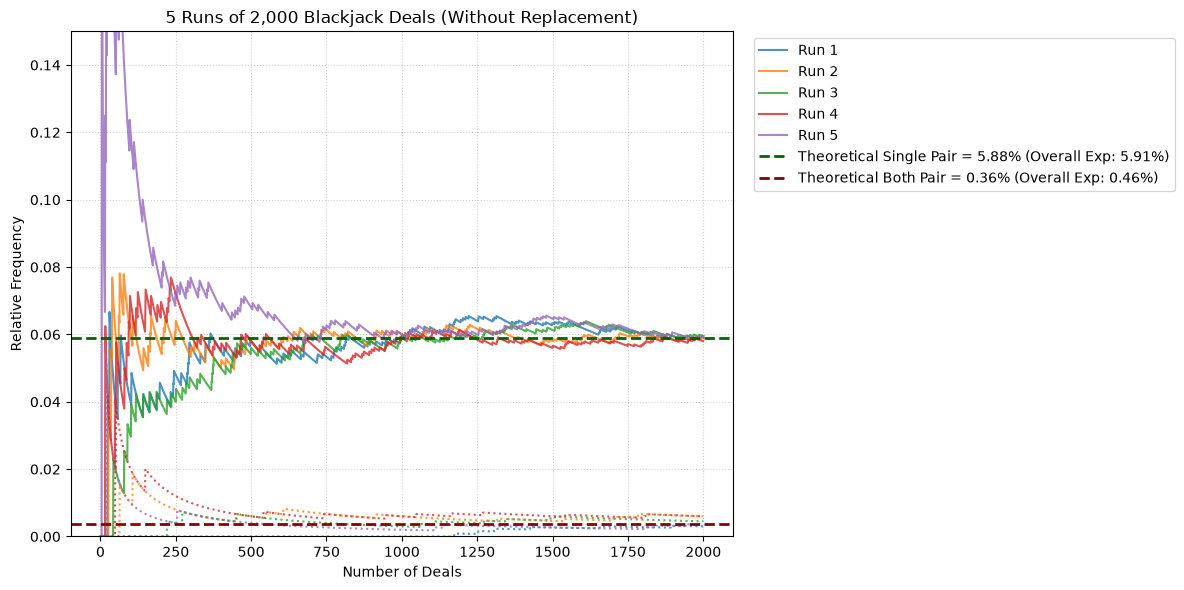

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================
# 1. SETUP SIMULATION PARAMETERS & RUN SIMULATIONS
# ==========================================
num_trials = 2000
num_runs = 5
ranks = ['2', '3', '4', '5', '6', '7', '8', '9', '10', 'J', 'Q', 'K', 'A']

# Create a standard 52-card deck (4 of each rank)
deck = np.array(ranks * 4)

all_runs = []

for run in range(1, num_runs + 1):
    # Deal 4 cards without replacement per trial (2 cards for Player 1, 2 cards for Player 2)
    card_draws = np.array([
        np.random.choice(deck, size=4, replace=False) for _ in range(num_trials)
    ])

    # Check for pairs (same value)
    player1_pair = card_draws[:, 0] == card_draws[:, 1]
    player2_pair = card_draws[:, 2] == card_draws[:, 3]
    both_pair = player1_pair & player2_pair

    df_run = pd.DataFrame({
        "trial_number": np.arange(1, num_trials + 1),
        "player1_pair": player1_pair,
        "player2_pair": player2_pair,
        "both_pair": both_pair,
    })

    # Cumulative relative frequencies
    df_run["rel_freq_p1"] = df_run["player1_pair"].cumsum() / df_run["trial_number"]
    df_run["rel_freq_both"] = df_run["both_pair"].cumsum() / df_run["trial_number"]
    df_run["run"] = f"Run {run}"

    all_runs.append(df_run)

# Concatenate all runs into a single DataFrame
all_runs = pd.concat(all_runs, ignore_index=True)

# Theoretical Probabilities (Without Replacement)
# P(Single Pair) = 3/51
p_single_theoretical = 3 / 51  # ~5.88%

# P(Both Pair) = (3/51) * (3/49)
p_both_theoretical = (3 / 51) * (3 / 49)  # ~0.36%

# ==========================================
# 2. DISPLAY EXPERIMENTAL VS THEORETICAL %
# ==========================================
print("=== FINAL EXPERIMENTAL PERCENTAGES (AT 2,000 DEALS) ===")
for run_name, group in all_runs.groupby("run"):
    final_p1_pct = group["rel_freq_p1"].iloc[-1] * 100
    final_both_pct = group["rel_freq_both"].iloc[-1] * 100
    print(
        f"{run_name}: Single Player Pair = {final_p1_pct:.2f}% | Both Players Pair = {final_both_pct:.2f}%"
    )

overall_p1_pct = all_runs["player1_pair"].mean() * 100
overall_both_pct = all_runs["both_pair"].mean() * 100

print("\n=== OVERALL EXPERIMENTAL PERCENTAGE (ALL 10,000 DEALS) ===")
print(f"Overall Single Player Pair: {overall_p1_pct:.2f}% (Theoretical: {p_single_theoretical * 100:.2f}%)")
print(f"Overall Both Players Pair:  {overall_both_pct:.2f}% (Theoretical: {p_both_theoretical * 100:.2f}%)\n")

# ==========================================
# 3. MULTI-RUN RELATIVE FREQUENCY LINE PLOT
# ==========================================
plt.figure(figsize=(12, 6))

# Plot relative frequency for 1 Person Getting a Pair (Solid Lines)
sns.lineplot(
    data=all_runs,
    x="trial_number",
    y="rel_freq_p1",
    hue="run",
    palette="tab10",
    alpha=0.8,
)

# Plot relative frequency for Both Getting a Pair (Dotted Lines)
sns.lineplot(
    data=all_runs,
    x="trial_number",
    y="rel_freq_both",
    hue="run",
    palette="tab10",
    legend=False,
    linestyle=":",
    alpha=0.8,
)

# Theoretical Reference Lines
plt.axhline(
    p_single_theoretical,
    color="darkgreen",
    linestyle="--",
    linewidth=2,
    label=f"Theoretical Single Pair = {p_single_theoretical * 100:.2f}% (Overall Exp: {overall_p1_pct:.2f}%)",
)
plt.axhline(
    p_both_theoretical,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"Theoretical Both Pair = {p_both_theoretical * 100:.2f}% (Overall Exp: {overall_both_pct:.2f}%)",
)

plt.title("5 Runs of 2,000 Blackjack Deals (Without Replacement)")
plt.xlabel("Number of Deals")
plt.ylabel("Relative Frequency")
plt.ylim(0, 0.15)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# Conclusion
What is the probability of a single player being dealt a pair of cards of the same value?Theoretical: When drawing 2 cards from a standard 52-card deck, the total possible 2-card combinations is $\binom{52}{2} = 1,326$. With 13 ranks and $\binom{4}{2} = 6$ ways to form a pair per rank, there are 78 pair combinations. The single equation for this probability is:$$P(\text{Single Pair}) = 13 \times \frac{\binom{4}{2}}{\binom{52}{2}} = \frac{3}{51} = \frac{1}{17} \approx 0.05882 \quad (5.88\%)$$Experimental: Across 10,000 total simulated deals, the overall experimental relative frequency for a single player receiving a pair was 5.91% (a percent error of approximately +0.51% relative to the theoretical $5.88\%$).
the graph shows that after the 2000 runs and 5 trials totaling to 10000 runs the expermental value begins to level out. this is becuase of a phenominon know as the theory of large numbers in which case experiment approaches theoretical. this concept is important becuase if we where to had used the first 250 deals then run 5 would have significantly skewed the chance of matching values being dealt to a number cloaser to 10% which is DOUBLE the theoretical value.
In short the chance that during a game of blackjack you are dealt a hand with 2 cards of the same value is $5.88\%$ in theory and $5.91\%$ in this experiment which can be summed up to a margine of error since it is only $0.03\%$ off of the theoretical value